# Value-Suppressing Uncertainty Palette (VSUP) Map

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

A map palette that spends colour on precision only where the estimate is precise. Certain estimates get many distinguishable shades. As uncertainty grows, neighbouring value bins merge and their colours fade toward gray, so the reader cannot over-read a noisy estimate. A conventional bivariate map keeps every value × uncertainty combination distinct, which is hard to decode and still invites precise readings of unreliable numbers.

## When to use

- Mapping estimates whose precision varies a lot between regions (survey rates, small-area statistics, model estimates)
- The reader will make decisions from the map and should be cautious where data is thin
- Showing value and uncertainty together in one map instead of two side-by-side maps

## Avoid when

- All estimates have similar precision (a normal choropleth is simpler)
- Readers must look up exact values for every region (use a table with intervals)
- The audience has never seen the palette and there is no room for the legend

## Alternatives

- Choropleth plus a separate map of the margin of error
- Dot or interval plot of the estimates, sorted, with confidence intervals
- Bayesian surprise map

## Design tips

- The legend is part of the method; always show the arc (wedge) legend, outer ring = most certain
- Choose uncertainty thresholds that mean something to the reader (for example, standard error in percentage points)
- Keep one sequential hue for value; uncertainty is shown by bin merging and fading, not by a second hue
- Compared with the bivariate map: fewer colour classes to learn, and uncertain regions no longer look precise

## Example

Simulated survey estimates of mortgage delinquency for 50 states and DC. Large states have thousands of respondents, small states fewer than 250, so their standard errors differ several-fold. Left: a conventional 4 × 4 bivariate palette. Right: a 4-level VSUP.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import matplotlib as mpl
from matplotlib.patches import Wedge

### Data

In [2]:
STATES = ["AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "DC", "FL", "GA", "HI", "ID", "IL", "IN",
          "IA", "KS", "KY", "LA", "ME", "MD", "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH",
          "NJ", "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC", "SD", "TN", "TX", "UT",
          "VT", "VA", "WA", "WV", "WI", "WY"]
GRID = {"AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11),
        "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4), "MN": (2, 5), "IL": (2, 6),
        "WI": (2, 7), "MI": (2, 8), "NY": (2, 9), "RI": (2, 10), "MA": (2, 11),
        "OR": (3, 1), "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5), "IN": (3, 6),
        "OH": (3, 7), "PA": (3, 8), "NJ": (3, 9), "CT": (3, 10),
        "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5), "KY": (4, 6),
        "WV": (4, 7), "VA": (4, 8), "MD": (4, 9), "DE": (4, 10),
        "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6), "NC": (5, 7),
        "SC": (5, 8), "DC": (5, 9),
        "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
        "HI": (7, 0), "TX": (7, 4), "FL": (7, 9)}
BIG = {"CA", "TX", "FL", "NY", "PA", "IL", "OH", "GA", "NC", "MI", "NJ", "VA", "WA", "AZ", "MA"}
SMALL = {"WY", "VT", "DC", "AK", "ND", "SD", "DE", "RI", "MT", "ME", "NH", "HI", "WV", "ID", "NE"}

rng = np.random.default_rng(31)
# Survey of mortgage holders: big states get big samples, small states small ones.
n = np.array([rng.integers(2500, 6000) if s in BIG else rng.integers(60, 250) if s in SMALL
              else rng.integers(400, 1500) for s in STATES])
true_rate = np.clip(rng.normal(4.5, 1.3, len(STATES)), 1.5, 8.5) / 100
observed = rng.binomial(n, true_rate) / n
df = pd.DataFrame({"state": STATES, "sample_size": n, "rate_pct": 100 * observed,
                   "se_pct": 100 * np.sqrt(np.maximum(observed * (1 - observed), 1e-4) / n)})
df["row"] = df["state"].map(lambda s: GRID[s][0])
df["col"] = df["state"].map(lambda s: GRID[s][1])
df.sort_values("se_pct").head()

,state,sample_size,rate_pct,se_pct,row,col
47,WA,4583,2.465634,0.229070,2,1
21,MA,4565,3.154436,0.258690,2,11
13,IL,2679,1.829041,0.258891,2,6
4,CA,4503,3.353320,0.268275,4,1
32,NY,4415,3.488109,0.276134,2,9


### Plot

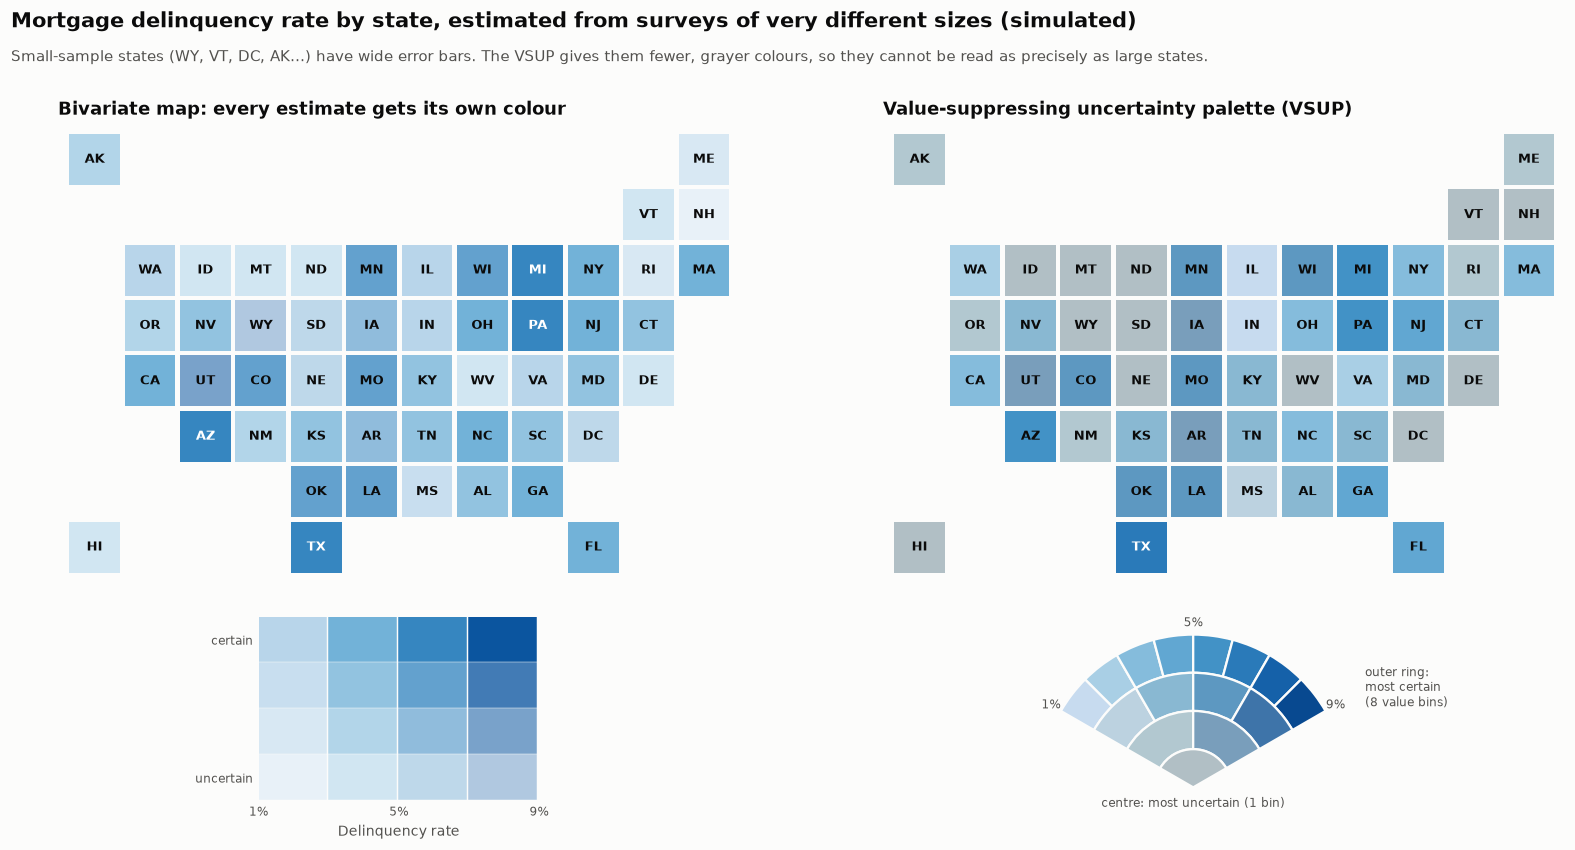

In [3]:
VMIN, VMAX = 1.0, 9.0                 # value domain (%)
U_EDGES = [0.4, 0.8, 1.4]             # standard-error thresholds (pp) -> 4 uncertainty levels
LEVELS = 4                            # level 0 = most certain (8 value bins) ... level 3 = 1 bin
seq = mpl.colormaps["Blues"]
gray = np.array(mpl.colors.to_rgb("#c9c8c3"))


def unc_level(se):
    return int(np.searchsorted(U_EDGES, se))


def vsup_color(value, level):
    """VSUP: fewer value bins as uncertainty grows, and colors fade toward gray."""
    bins = 2 ** (LEVELS - 1 - level)
    t = np.clip((value - VMIN) / (VMAX - VMIN), 0, 0.999)
    centre = (np.floor(t * bins) + 0.5) / bins
    base = np.array(seq(0.2 + 0.75 * centre)[:3])
    return tuple(base + (gray - base) * (level / (LEVELS - 1)) * 0.8)


def bivariate_color(value, level):
    """Naive bivariate map: 4 value bins x 4 uncertainty bins, all kept distinct."""
    t = np.clip((value - VMIN) / (VMAX - VMIN), 0, 0.999)
    centre = (np.floor(t * 4) + 0.5) / 4
    base = np.array(seq(0.2 + 0.75 * centre)[:3])
    return tuple(base + (np.ones(3) - base) * level / LEVELS * 0.9)


def ink(rgb):
    lum = 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2]
    return "white" if lum < 0.5 else "#0b0b0b"


def draw_map(ax, color_fn, title):
    for _, r in df.iterrows():
        c = color_fn(r.rate_pct, unc_level(r.se_pct))
        ax.add_patch(plt.Rectangle((r.col, -r.row), 0.92, 0.92, color=c, linewidth=0))
        ax.text(r.col + 0.46, -r.row + 0.46, r.state, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=ink(c))
    ax.set_xlim(-0.2, 12.1); ax.set_ylim(-7.2, 1.1)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=12)


fig = plt.figure(figsize=(15, 7.6))
ax_l = fig.add_axes([0.01, 0.30, 0.47, 0.55])
ax_r = fig.add_axes([0.51, 0.30, 0.47, 0.55])
draw_map(ax_l, bivariate_color, "Bivariate map: every estimate gets its own colour")
draw_map(ax_r, vsup_color, "Value-suppressing uncertainty palette (VSUP)")

# Square legend for the bivariate map
lg = fig.add_axes([0.16, 0.04, 0.17, 0.22])
for lvl in range(LEVELS):
    for b in range(4):
        v = VMIN + (b + 0.5) / 4 * (VMAX - VMIN)
        lg.add_patch(plt.Rectangle((b, lvl), 0.96, 0.96, color=bivariate_color(v, lvl)))
lg.set_xlim(0, 4); lg.set_ylim(LEVELS, 0)
lg.set_xticks([0, 2, 4], [f"{VMIN:.0f}%", f"{(VMIN + VMAX) / 2:.0f}%", f"{VMAX:.0f}%"])
lg.set_yticks([0.5, 3.5], ["certain", "uncertain"])
lg.tick_params(length=0, labelsize=8); lg.grid(False)
for s in lg.spines.values():
    s.set_visible(False)
lg.set_xlabel("Delinquency rate", fontsize=9)

# Arc (wedge) legend for the VSUP: outer ring = low uncertainty, many value bins;
# centre = high uncertainty, a single "we don't know" bin.
wl = fig.add_axes([0.62, 0.0, 0.25, 0.3])
a0, a1 = 30, 150   # arc spans 120 degrees; value increases left -> right
for lvl in range(LEVELS):
    bins = 2 ** (LEVELS - 1 - lvl)
    r_out = LEVELS - lvl
    for b in range(bins):
        v = VMIN + (b + 0.5) / bins * (VMAX - VMIN)
        th1 = a1 - (a1 - a0) * b / bins
        th0 = a1 - (a1 - a0) * (b + 1) / bins
        wl.add_patch(Wedge((0, 0), r_out, th0, th1, width=1, facecolor=vsup_color(v, lvl),
                           edgecolor="#fcfcfb", linewidth=1.5))
wl.set_xlim(-4.6, 6.2); wl.set_ylim(-0.3, 4.4); wl.set_aspect("equal"); wl.axis("off")
for frac, lab in ((0, f"{VMIN:.0f}%"), (0.5, f"{(VMIN + VMAX) / 2:.0f}%"), (1, f"{VMAX:.0f}%")):
    th = np.deg2rad(a1 - (a1 - a0) * frac)
    wl.text(4.3 * np.cos(th), 4.3 * np.sin(th), lab, ha="center", va="center", fontsize=8, color="#52514e")
wl.text(0, -0.25, "centre: most uncertain (1 bin)", ha="center", va="top", fontsize=8, color="#52514e")
wl.text(4.5, 2.6, "outer ring:\nmost certain\n(8 value bins)", ha="left", va="center", fontsize=8, color="#52514e")

fig.suptitle("Mortgage delinquency rate by state, estimated from surveys of very different sizes (simulated)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=0.985)
fig.text(0.01, 0.925, "Small-sample states (WY, VT, DC, AK…) have wide error bars. The VSUP gives them fewer, "
         "grayer colours, so they cannot be read as precisely as large states.", fontsize=10, color="#52514e")
plt.show()

## How to read it

On the VSUP map, dark, saturated tiles are estimates that are both high and reliable. Grayish tiles say "this estimate is uncertain": the moderately uncertain ones keep only a low/high distinction, and the grayest (the smallest samples, such as WY, MT and HI) carry no value information at all. Compare a small state with a large state of similar colour on the left map: on the right, the small state loses its detail because its survey was too small to support it.

## Reference

This method comes from the research literature:

- Correll, M., Moritz, D. & Heer, J. (2018). Value-suppressing uncertainty palettes. Proceedings of the ACM CHI Conference on Human Factors in Computing Systems (CHI 2018). <https://doi.org/10.1145/3173574.3174216>

---
Standalone script: [`vsup_map.py`](vsup_map.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)